In [40]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Базовая работа с изображением

In [41]:
image = cv2.imread('sar_2_color.jpg')

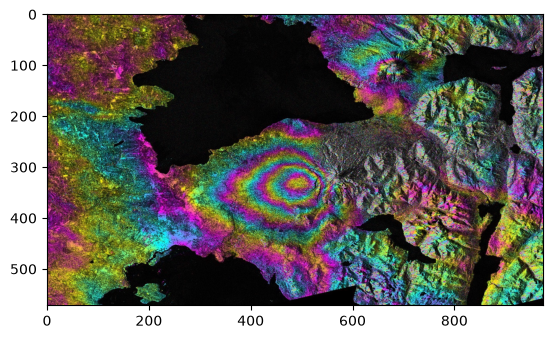

In [42]:
plt.imshow(image)

In [43]:
image.shape # h,w,c

(572, 974, 3)

In [44]:
image[250,250] # b,g,r

array([12, 12, 12], dtype=uint8)

In [45]:
# ROI
img_roi = image[100:200, 500:700]

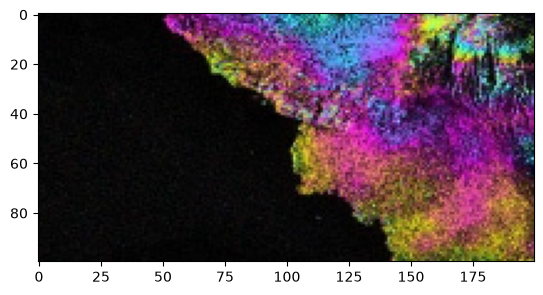

In [46]:
plt.imshow(img_roi)

In [47]:
b,g,r = cv2.split(image)

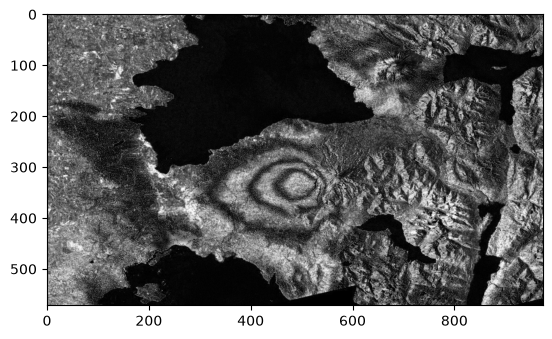

In [48]:
plt.imshow(b, cmap = 'gray')

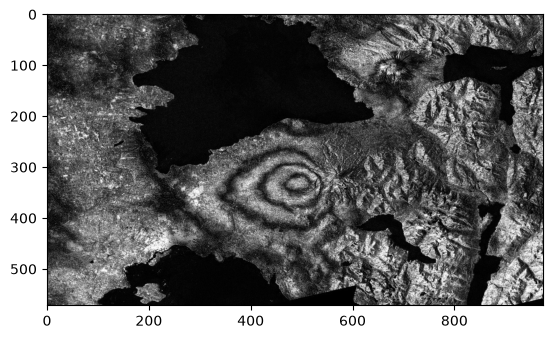

In [49]:
plt.imshow(g, cmap = 'gray')

In [50]:
# alternative approach
b = image[:,:,0]

In [51]:
import copy

image2 = copy.deepcopy(image)

In [52]:
image2[50:100,50:100] = [0,0,0]

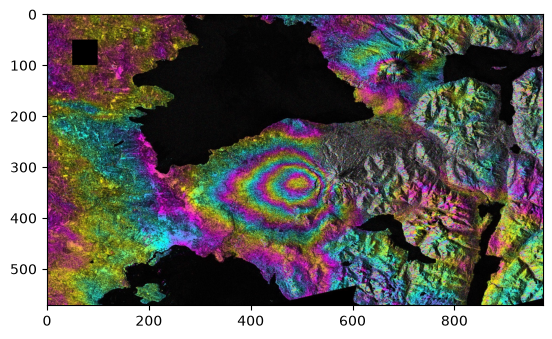

In [53]:
plt.imshow(image2)

In [54]:
# empty image
image_template = np.zeros(image.shape,np.uint8)

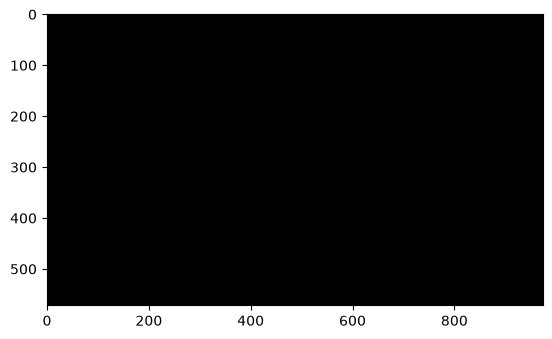

In [55]:
plt.imshow(image_template)

Размер изображения: (400, 600)


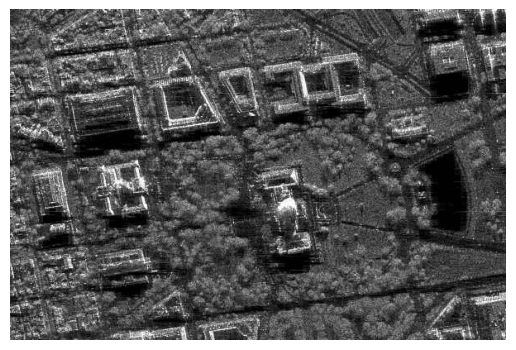

In [56]:

import cv2
import matplotlib.pyplot as plt

# Загрузка изображения в оттенках серого
image = cv2.imread("sar_1_gray.jpg", cv2.IMREAD_GRAYSCALE)

# Проверка загрузки изображения
if image is None:
    print("Ошибка: изображение не найдено")
else:
    print("Размер изображения:", image.shape)

    # Отображение изображения
    plt.imshow(image, cmap="gray")
    plt.axis("off")
    plt.show()


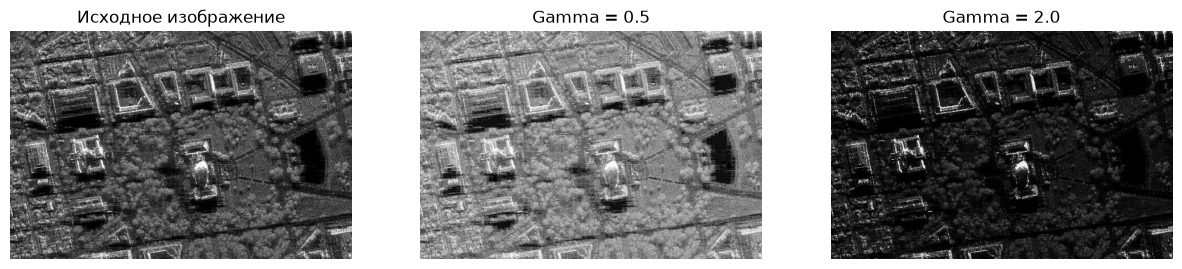

In [61]:

# Сравнение исходного изображения с изображениями после гамма-коррекции

# Gamma = 0.5
mse_05 = mean_squared_error(image, gamma_less_1)
ssim_05 = structural_similarity(image, gamma_less_1, data_range=255)

# Gamma = 2.0
mse_20 = mean_squared_error(image, gamma_greater_1)
ssim_20 = structural_similarity(image, gamma_greater_1, data_range=255)

# Вывод результатов
print("Gamma = 0.5")
print("MSE:", mse_05)
print("SSIM:", ssim_05)

print("\nGamma = 2.0")
print("MSE:", mse_20)
print("SSIM:", ssim_20)


Gamma = 0.5
MSE: 3250.429145833333
SSIM: 0.7875008686792752

Gamma = 2.0
MSE: 2383.7636375
SSIM: 0.5270459922820343


In [ ]:

# Построение гистограммы изображения

import numpy as np

# Функция гамма-коррекции
def gamma_correction(image, gamma):
    normalized = image / 255.0
    corrected = np.power(normalized, gamma) * 255.0
    return np.clip(corrected, 0, 255).astype(np.uint8)

# Коррекция с гамма меньше 1 и больше 1
gamma_less_1 = gamma_correction(image, 0.5)
gamma_greater_1 = gamma_correction(image, 2.0)

# Отображение результатов
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Исходное изображение")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gamma_less_1, cmap="gray", vmin=0, vmax=255)
plt.title("Gamma = 0.5")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gamma_greater_1, cmap="gray", vmin=0, vmax=255)
plt.title("Gamma = 2.0")
plt.axis("off")

plt.show()


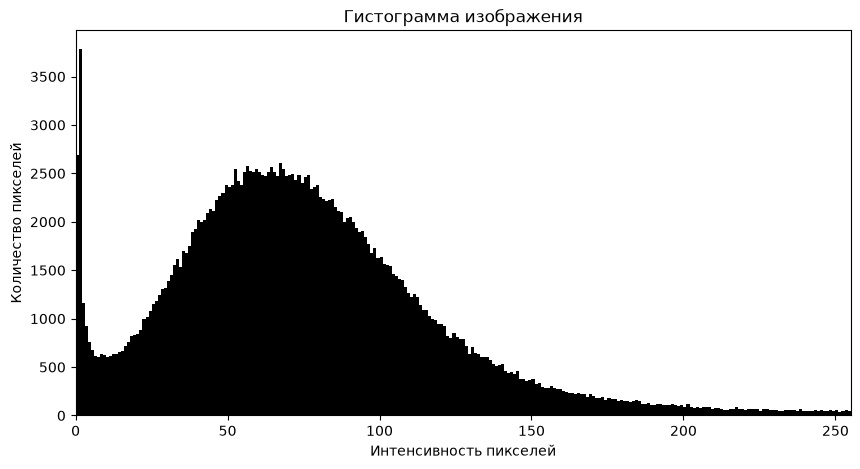

In [20]:

plt.figure(figsize=(10, 5))
plt.hist(image.ravel(), bins=256, range=(0, 256), color="black")
plt.title("Гистограмма изображения")
plt.xlabel("Интенсивность пикселей")
plt.ylabel("Количество пикселей")
plt.xlim(0, 255)
plt.show()


# Конвертация цветовых моделей

In [31]:
image_template[0,0]

array([0, 0, 0], dtype=uint8)

In [32]:
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

In [33]:
image_gray[0,0]

40

In [34]:
image_gray.shape

(572, 974)

In [35]:
image_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV) 

In [36]:
image_hsv.shape

(572, 974, 3)

In [37]:
image_hsv[0,0]

array([117, 143,  75], dtype=uint8)

In [38]:
image[0,0]

array([75, 37, 33], dtype=uint8)

In [39]:
image_lab = cv2.cvtColor(image, cv2.COLOR_BGR2Lab)

In [40]:
image_lab[0,0]

array([ 42, 139, 104], dtype=uint8)

# Пороговая фильтрация

In [67]:
_,thresh1 = cv2.threshold(image_gray,200,255,cv2.THRESH_BINARY)

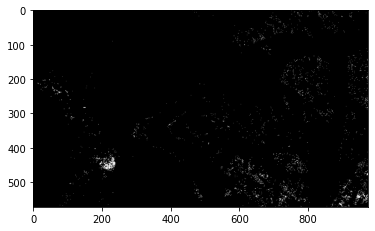

In [68]:
plt.imshow(thresh1, cmap='gray')

In [43]:
thresh1[thresh1==100].sum()

0

# Построение гистограммы

In [44]:
histSize = 256
histRange = (0, 256)
accumulate = False

b_hist = cv2.calcHist([b], [0], None, [histSize], histRange, accumulate=accumulate)

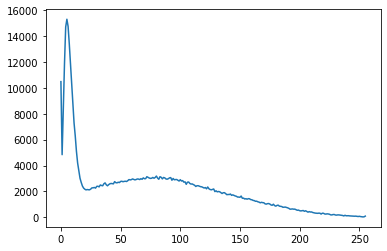

In [45]:
plt.plot(b_hist)

In [46]:
b_hist_cum = b_hist.cumsum()

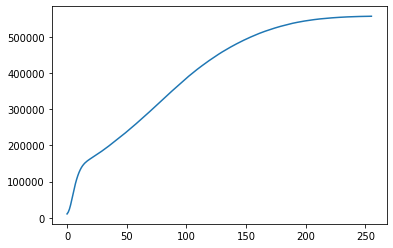

In [47]:
plt.plot(b_hist_cum)

In [49]:
b_hist_norm = b_hist /  (image.shape[0] * image.shape[1])

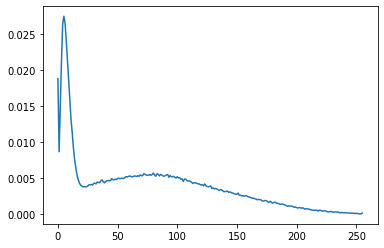

In [50]:
plt.plot(b_hist_norm)

# Сравнение двух изображений

In [53]:
from skimage.metrics import structural_similarity, mean_squared_error

(ssim, diff) = structural_similarity(image_gray, image_gray, full=True)
diff = (diff * 255).astype("uint8")
print("SSIM: {}".format(ssim))

SSIM: 1.0


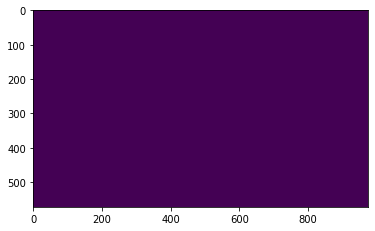

In [54]:
plt.imshow(diff)

In [55]:
mse = mean_squared_error(image_gray, image_gray)
mse

0.0

# Статистические характеристики изображений

In [56]:
mean = image_gray.mean()

In [57]:
std = image_gray.std()

In [58]:
print(mean,std)

67.41225535245043 52.016191875959635


In [60]:
eq_gray = cv2.equalizeHist(image_gray)

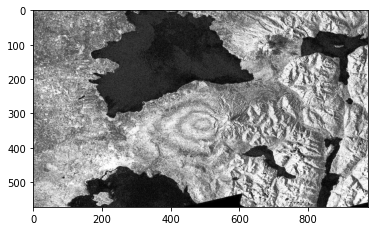

In [63]:
plt.imshow(eq_gray, cmap="gray")


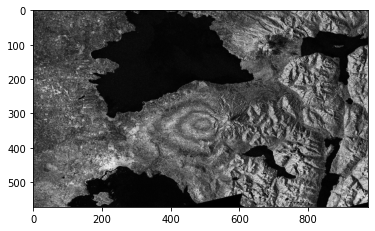

In [64]:
plt.imshow(image_gray, cmap="gray")

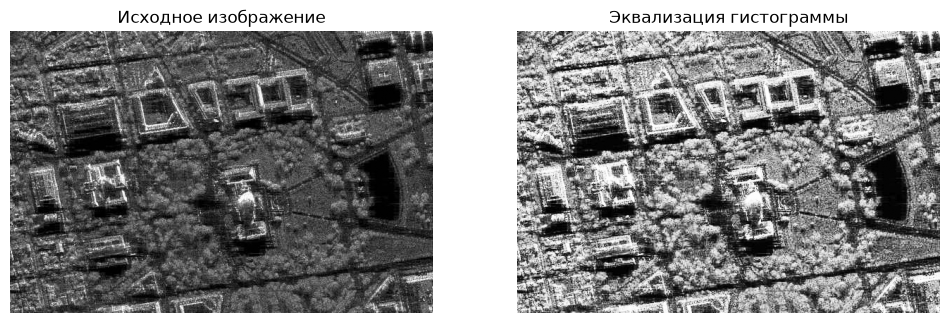

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Загрузка исходного изображения
gray_image = cv2.imread("sar_1_gray.jpg", cv2.IMREAD_GRAYSCALE)

if gray_image is None:
    raise FileNotFoundError("Не найден файл sar_1_gray.jpg")

# Собственная реализация эквализации гистограммы
def histogram_equalization(img):
    hist = np.bincount(img.ravel(), minlength=256)
    cdf = hist.cumsum()

    nonzero = np.flatnonzero(hist)
    cdf_min = cdf[nonzero[0]]

    denominator = img.size - cdf_min

    if denominator == 0:
        return img.copy()

    lut = np.round(
        (cdf - cdf_min) * 255 / denominator
    )

    lut = np.clip(lut, 0, 255).astype(np.uint8)

    return lut[img]

# Применение собственной реализации
eq_gray = histogram_equalization(gray_image)

# Отображение результатов
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray", vmin=0, vmax=255)
plt.title("Исходное изображение")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(eq_gray, cmap="gray", vmin=0, vmax=255)
plt.title("Эквализация гистограммы")
plt.axis("off")

plt.show()


Исходное изображение:
Среднее значение: 74.94157083333333
Стандартное отклонение: 43.658465466227916

Эталонное изображение eq_gray:
Среднее значение: 127.02563333333333
Стандартное отклонение: 74.26964841889017


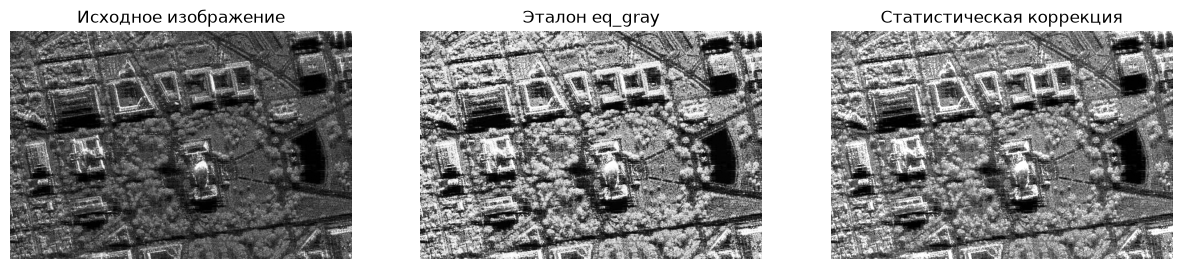

In [64]:

# Статистические характеристики исходного изображения
mean_original = gray_image.mean()
std_original = gray_image.std()

# Статистические характеристики эталонного изображения eq_gray
mean_reference = eq_gray.mean()
std_reference = eq_gray.std()

print("Исходное изображение:")
print("Среднее значение:", mean_original)
print("Стандартное отклонение:", std_original)

print("\nЭталонное изображение eq_gray:")
print("Среднее значение:", mean_reference)
print("Стандартное отклонение:", std_reference)

# Собственная реализация статистической коррекции
if std_original > 0:
    corrected = (
        mean_reference
        + (gray_image.astype(np.float32) - mean_original)
        * std_reference / std_original
    )
else:
    corrected = gray_image.astype(np.float32)

stat_corrected = np.clip(corrected, 0, 255).astype(np.uint8)

# Отображение результата
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray_image, cmap="gray", vmin=0, vmax=255)
plt.title("Исходное изображение")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(eq_gray, cmap="gray", vmin=0, vmax=255)
plt.title("Эталон eq_gray")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(stat_corrected, cmap="gray", vmin=0, vmax=255)
plt.title("Статистическая коррекция")
plt.axis("off")

plt.show()


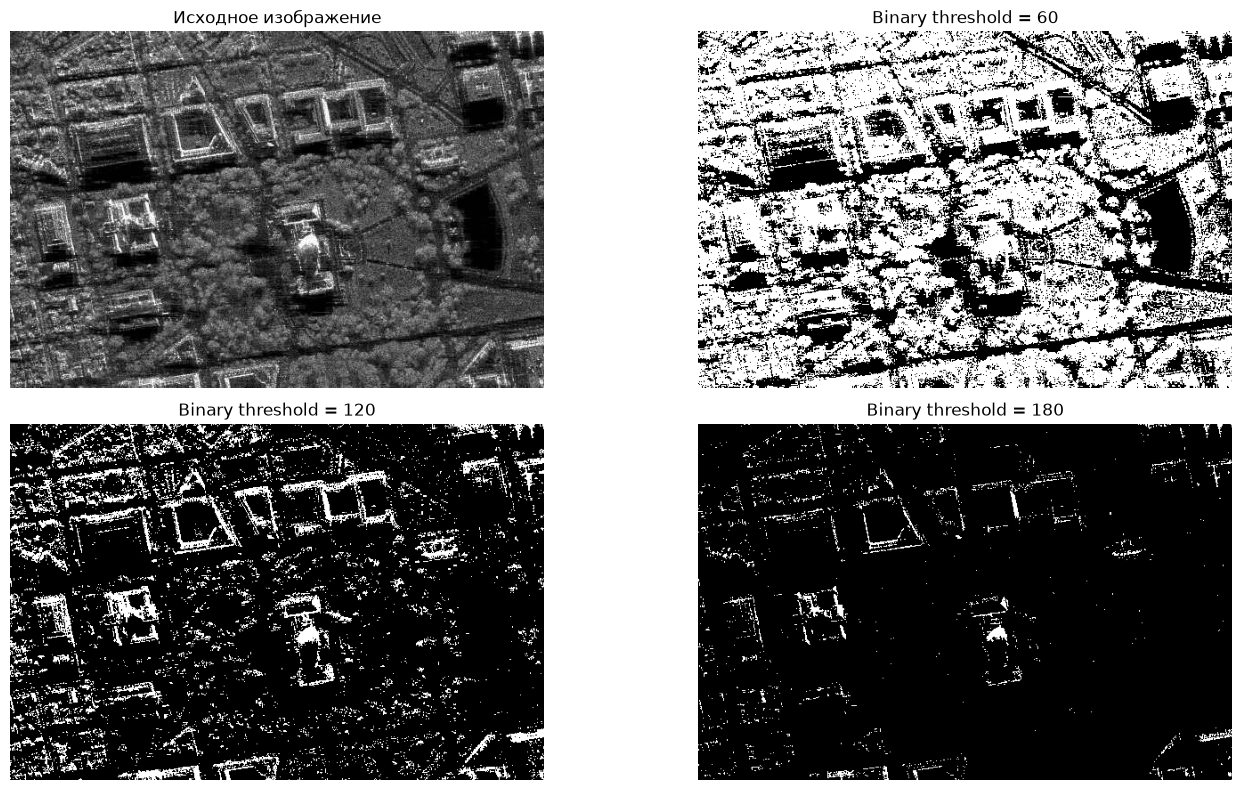

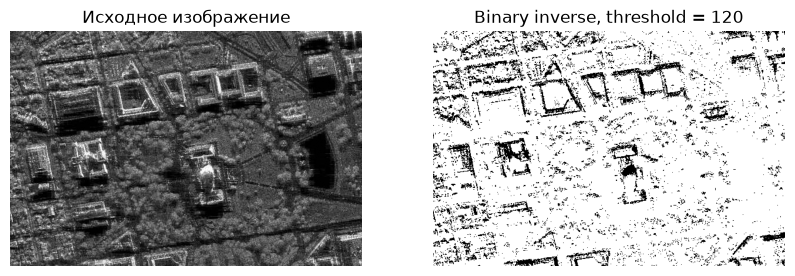

In [65]:

# Пороговая фильтрация с различными параметрами

thresholds = [60, 120, 180]

plt.figure(figsize=(15, 8))

# Исходное изображение
plt.subplot(2, 2, 1)
plt.imshow(gray_image, cmap="gray", vmin=0, vmax=255)
plt.title("Исходное изображение")
plt.axis("off")

# Бинарная фильтрация с разными порогами
for i, threshold in enumerate(thresholds, start=2):
    _, result = cv2.threshold(
        gray_image,
        threshold,
        255,
        cv2.THRESH_BINARY
    )

    plt.subplot(2, 2, i)
    plt.imshow(result, cmap="gray", vmin=0, vmax=255)
    plt.title(f"Binary threshold = {threshold}")
    plt.axis("off")

plt.tight_layout()
plt.show()

# Дополнительный тест: инвертированная бинарная фильтрация
_, binary_inv = cv2.threshold(
    gray_image,
    120,
    255,
    cv2.THRESH_BINARY_INV
)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray", vmin=0, vmax=255)
plt.title("Исходное изображение")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_inv, cmap="gray", vmin=0, vmax=255)
plt.title("Binary inverse, threshold = 120")
plt.axis("off")

plt.show()


In [ ]:
# 1. Загрузите изображение в оттенках серого sar_1_gray.jpg. 
# 2. постройте гистограмму
# 3. реализуйте алгоритм гамма коррекции с параметром гамма <1, >1.
# 4. Сравните исходное изображение, скорректированное при помощи гамма-фильтра. MSE, SSIM.
# 5. реализуйте алгоритм статистической цветокоррекции на основе статистики eq_gray.
# 6. Протестируйте работу алгоритмов пороговой фильтрации с различными параметрами.
# Для каждого решения - напечатайте результат
